# Robotics capstone 2: from masks and depth to 3D boxes and grasp poses

Notebook 01 turned words into instance masks. A robot arm needs more: **where** each object is
in metres, **how big** it is, and **how to pick it up**, expressed in a frame the arm
understands. This notebook builds that 3D half of the pipeline on one RGB-D frame of TUM
`fr1/desk`:

```
mask + sensor depth ──► object point cloud ──► support plane ──► gravity-aligned 3D box
      (camera model)      (erode, gate, SOR)       (RANSAC)          (min-area rectangle)
                                                                             │
          world-frame grasp  ◄── T_wc (motion capture) ◄── camera-frame grasp ◄── top-down
                                                                       antipodal grasp search
```

**What you'll learn**
- How lens distortion and the choice of intrinsics enter back-projection, and how to
  back-project *raw* pixels exactly with a per-pixel ray lookup table.
- Why a mask is not enough: border pixels, depth holes and background leaks, and the robust
  statistics (median/MAD gate, statistical outlier removal) that clean them up.
- Why a PCA box of a partial view is misleading, and how a support plane fixes the box's
  orientation and height.
- How a simple top-down parallel-jaw grasp planner works (width, collision and antipodal
  checks) and how to chain transforms $T_{wg} = T_{wc}\,T_{cg}$.
- How a monocular metric depth network compares with the depth sensor for this task.

**Prerequisites**: notebook 01; pinhole camera model and rigid transforms (projects 01, 07, 09).

## Setup

In [1]:
# --- Setup: imports, device, repo-relative paths and plotting style ---
# capstone.py holds the models and the pipeline; grasp3d.py the NumPy geometry that is shared
# with the ROS 2 node (it runs under the system Python of ROS 2 Jazzy as well).
import os
import sys
import warnings

os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
warnings.filterwarnings("ignore", category=UserWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import transformers
from IPython.display import display

from cvlab import device as cvdevice
from cvlab import viz
from cvlab.bench import benchmark
from cvlab.geometry import R_to_quat, angle_between_deg, invert_T
from cvlab.io import project_dir
from cvlab.metrics import align_depth_scale, depth_metrics

transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()

PROJECT = "15_robotics_capstone"
sys.path.insert(0, str(project_dir(PROJECT) / "scripts"))
import capstone as cap  # noqa: E402
import grasp3d as g3  # noqa: E402

device = cvdevice.setup(seed=0)
viz.set_style()
DEV = "cuda" if device.type == "cuda" else "cpu"
np.set_printoptions(precision=3, suppress=True)

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)


## 1. The 2D input: masks for frame 540

We reuse the cascade from notebook 01, Grounding DINO-T boxes → SAM 3 masks, on frame 540, and
free the GPU right after. Everything after this cell runs on the CPU with NumPy/SciPy, which is
why the same geometry code can run inside a ROS 2 node.

object 0: telephone        score 0.76, mask  16660 px
object 1: game controller  score 0.65, mask  12307 px
object 2: keyboard         score 0.52, mask   6864 px
object 3: book             score 0.55, mask  15090 px
object 4: cereal box       score 0.56, mask  13554 px
object 5: book             score 0.38, mask  21739 px


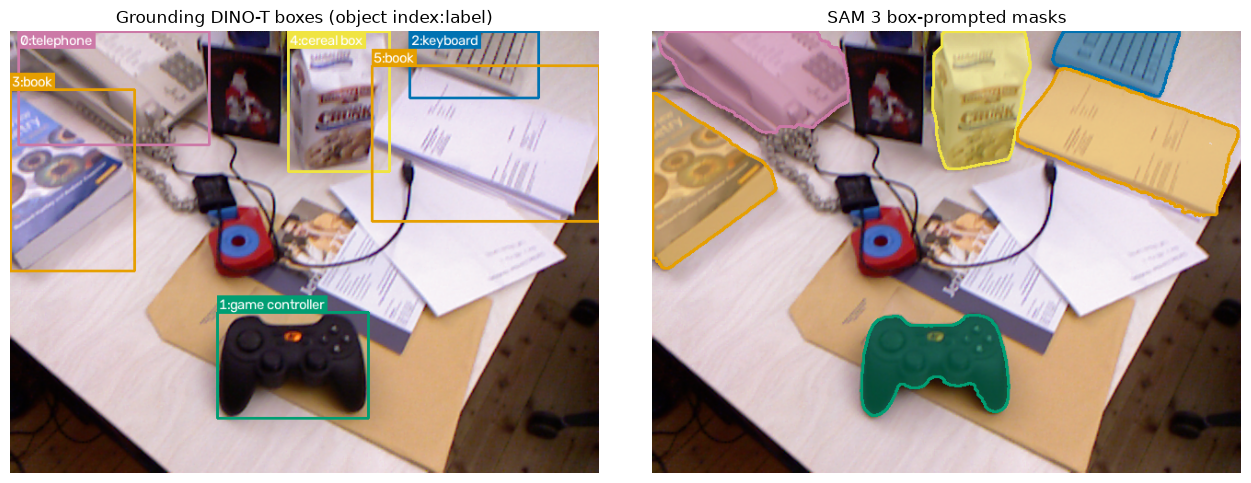

In [2]:
# --- Text -> boxes -> masks on frame 540, then free the GPU ---
# T_wc is the motion-capture camera-to-world pose interpolated at the *depth* timestamp
# (TUM RGB and depth images are up to 20 ms apart; the 3D points come from the depth image).
frames = cap.load_frames()
QUERIES = cap.QUERIES
QCOL = {q: viz.color(k) for k, q in enumerate(QUERIES)}
FID = 540
rgb, depth = frames.rgb(FID), frames.depth(FID)
T_wc = frames.pose(FID, at="depth")
gdino = cap.GroundingDinoDetector(DEV)
dets = gdino.detect(rgb, QUERIES)
seg = cap.BoxSegmenter("sam3", DEV)
seg.set_image(rgb)
masks, _ = seg.segment(dets.boxes)
del gdino, seg
cap.free()
for k, (lab, s) in enumerate(zip(dets.labels, dets.scores)):
    print(f"object {k}: {lab:16s} score {s:.2f}, mask {masks[k].sum():6d} px")
ids = [QUERIES.index(lab) for lab in dets.labels]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].imshow(viz.draw_boxes(rgb, dets.boxes, labels=[f"{k}:{lab}" for k, lab in enumerate(dets.labels)],
                            class_ids=ids))
ax[0].set_title("Grounding DINO-T boxes (object index:label)")
ax[1].imshow(viz.overlay_masks(rgb, masks, alpha=0.45, colors=[QCOL[lab] for lab in dets.labels]))
ax[1].set_title("SAM 3 box-prompted masks")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

## 2. Camera model: back-projecting raw pixels through a distorted lens

A pixel $(u, v)$ with depth $z$ back-projects to

$$ X = z\,\begin{bmatrix} x_n \\ y_n \\ 1 \end{bmatrix},\qquad
   (x_n, y_n) = \mathrm{undistort}\!\left(\tfrac{u - c_x}{f_x}, \tfrac{v - c_y}{f_y}\right). $$

Without distortion, $(x_n, y_n)$ is just the normalised pixel. The fr1 Kinect's RGB lens has
noticeable radial distortion ($k_1 = 0.262,\ k_2 = -0.953,\ k_3 = 1.163$), and inverting the
distortion model has no closed form. Instead of undistorting (resampling) the images, we compute
the ray of **every raw pixel once** with an iterative solver (`cv2.undistortPoints`) and store it
in a $480\times640\times2$ lookup table. Back-projection then stays an exact per-pixel multiply,
and masks never need to be warped.

TUM offers two calibrations for `fr1`: its own RGB calibration *with* distortion, and the ROS
default $f = 525$ px *without* distortion (recommended by TUM for the factory-registered
depth). We keep both, plus "fr1 without distortion", and compare their effect in notebook 03.

distortion shift: 0.00 px at the principal point, median 4.6 px, max 24.3 px (image corner)
ray angle 'fr1 + distortion' vs 'fr1, no distortion': median 0.43 deg, max 1.70 deg -> 30 mm lateral at 1 m
ray angle 'fr1 + distortion' vs 'ROS default': median 1.48 deg, max 1.78 deg -> 31 mm lateral at 1 m


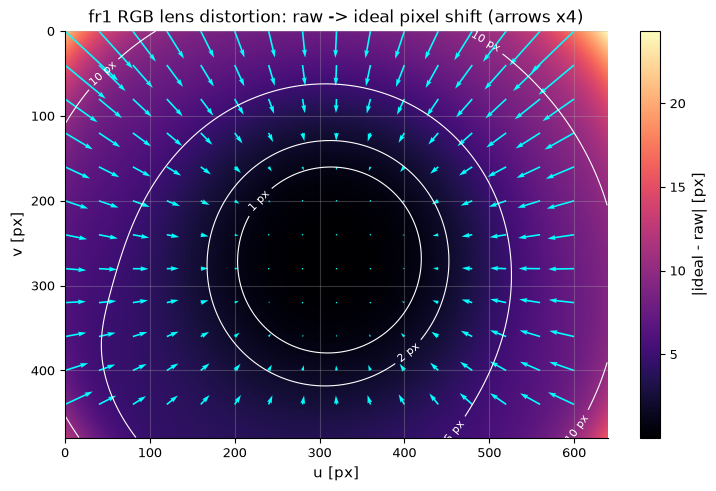

In [3]:
# --- Ray lookup tables for the three camera models and the size of the distortion ---
# `ideal` = where each raw pixel would land in an undistorted pinhole image with the same K.
W, H = 640, 480
rays = {name: g3.pixel_rays(K, dist, W, H) for name, (K, dist) in cap.CAMERAS.items()}
K, D = cap.CAMERAS[cap.DEFAULT_CAMERA]
R = rays[cap.DEFAULT_CAMERA]  # (H, W, 2) normalised rays used from here on
u, v = np.meshgrid(np.arange(W), np.arange(H))
ideal = R * [K[0, 0], K[1, 1]] + [K[0, 2], K[1, 2]]
shift = np.hypot(ideal[..., 0] - u, ideal[..., 1] - v)
print(f"distortion shift: {shift[int(K[1, 2]), int(K[0, 2])]:.2f} px at the principal point, "
      f"median {np.median(shift):.1f} px, max {shift.max():.1f} px (image corner)")
ray_dirs = {n: np.dstack([r, np.ones((H, W))]) for n, r in rays.items()}
for n in ["fr1, no distortion", "ROS default"]:
    a, b = ray_dirs[cap.DEFAULT_CAMERA], ray_dirs[n]
    cos = (a * b).sum(-1) / np.linalg.norm(a, axis=-1) / np.linalg.norm(b, axis=-1)
    ang = np.degrees(np.arccos(np.clip(cos, -1, 1)))
    print(f"ray angle '{cap.DEFAULT_CAMERA}' vs '{n}': median {np.median(ang):.2f} deg, "
          f"max {ang.max():.2f} deg -> {1000 * np.tan(np.radians(ang.max())):.0f} mm lateral at 1 m")

fig, ax = plt.subplots(figsize=(7.5, 4.8))
im = ax.imshow(shift, cmap="magma")
cs = ax.contour(shift, levels=[1, 2, 5, 10], colors="w", linewidths=0.8)
ax.clabel(cs, fmt="%g px", fontsize=8)
s = 40
ax.quiver(u[::s, ::s], v[::s, ::s], (ideal[..., 0] - u)[::s, ::s], (ideal[..., 1] - v)[::s, ::s],
          color="cyan", angles="xy", scale_units="xy", scale=0.25, width=0.003)
fig.colorbar(im, ax=ax, label="|ideal - raw| [px]")
ax.set_title("fr1 RGB lens distortion: raw -> ideal pixel shift (arrows x4)")
ax.set_xlabel("u [px]")
ax.set_ylabel("v [px]")
plt.show()

## 3. From mask to a clean object point cloud

Back-projecting every mask pixel naively gives a messy cloud:

- **mask borders**: the RGB-to-depth registration is off by a pixel or two and depth at object
  edges is a mix of foreground and background ("flying pixels") → erode the mask by 3 px;
- **holes**: no depth on dark or shiny parts → those pixels are simply absent;
- **leaks**: where the mask spills over the edge, the cloud gets a second, far-away cluster →
  a **depth-mode gate** around the median depth,
  $|z - \tilde z| < \max(3 \cdot 1.4826\,\mathrm{MAD}(z),\ 5\,\mathrm{cm})$;
  $1.4826\,\mathrm{MAD}$ is a robust estimate of the standard deviation, untouched by the leak;
- **isolated noise** → statistical outlier removal (drop points whose mean distance to their 16
  nearest neighbours is more than 2 σ above average), then a 5 mm voxel grid.

The table shows how many points survive each step for every object.

In [4]:
# --- Object clouds for every mask, with the point count after each cleaning step ---
# g3.object_cloud returns None if fewer than 30 valid points remain.
clouds, rows = {}, []
for k, (lab, m) in enumerate(zip(dets.labels, masks)):
    c = g3.object_cloud(depth, m, R, rgb)
    clouds[k] = c
    raw, _ = g3.backproject(depth, R, m)
    rows.append({"object": f"{k}:{lab}", "mask px": int(m.sum()), "with depth": len(raw),
                 "eroded + depth": None if c is None else c.n_valid,
                 "after gate": None if c is None else c.n_gated,
                 "after SOR": None if c is None else c.n_inliers,
                 "after 5 mm voxels": None if c is None else len(c.points),
                 "depth coverage [%]": round(100 * len(raw) / max(m.sum(), 1), 1)})
funnel = pd.DataFrame(rows).set_index("object")
display(funnel)

,mask px,with depth,eroded + depth,after gate,after SOR,after 5 mm voxels,depth coverage [%]
object,,,,,,,
0:telephone,16660,9770,8808,8808,8752,1163,58.6
1:game controller,12307,11337,9631,8722,8707,570,92.1
2:keyboard,6864,1793,1317,1317,1284,256,26.1
3:book,15090,14973,13159,13117,12737,1482,99.2
4:cereal box,13554,8838,8179,8179,7830,835,65.2
5:book,21739,17953,16194,16194,15801,2480,82.6


Let us look at one object in 3D before and after cleaning. Points are plotted with "up" =
$-y$ of the camera (the optical frame has $y$ pointing down), so the view resembles the image.

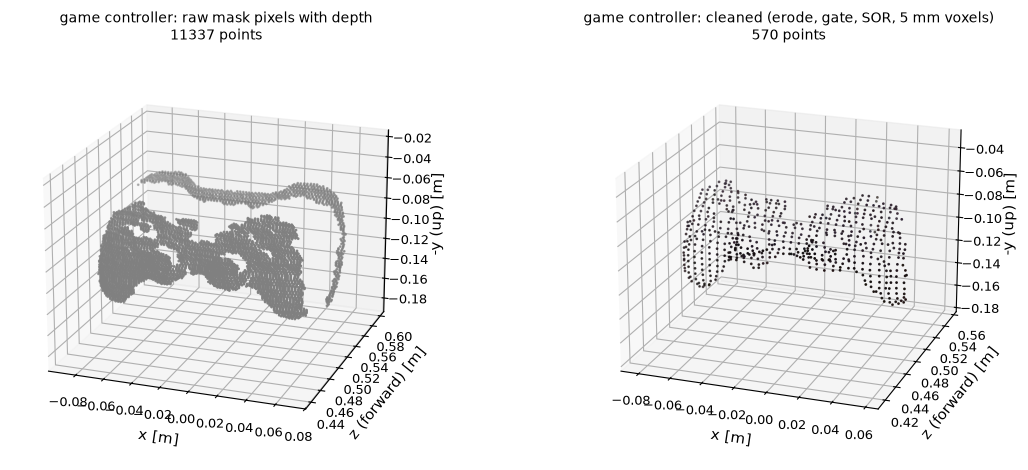

raw depth spread: 0.464-0.571 m (1-99th pct); cleaned: 0.463-0.509 m


In [5]:
# --- Raw vs cleaned cloud of one object ---
# Raw = all mask pixels with depth (no erosion, no gate); grey points are what cleaning removed.
k_obj = dets.labels.index("game controller") if "game controller" in dets.labels else 0
raw, _ = g3.backproject(depth, R, masks[k_obj])
clean = clouds[k_obj].points


def xyz_up(P):
    """Camera optical frame -> plotting frame (x right, z forward, -y up)."""
    return P[:, 0], P[:, 2], -P[:, 1]


fig = plt.figure(figsize=(12, 4.8))
for j, (title, P, col) in enumerate([("raw mask pixels with depth", raw, "0.5"),
                                     ("cleaned (erode, gate, SOR, 5 mm voxels)", clean,
                                      clouds[k_obj].colors)]):
    ax = fig.add_subplot(1, 2, j + 1, projection="3d")
    ax.scatter(*xyz_up(P[:: max(1, len(P) // 4000)]), s=1,
               c=col if isinstance(col, str) else col[:: max(1, len(P) // 4000)])
    ax.set_title(f"{dets.labels[k_obj]}: {title}\n{len(P)} points", fontsize=10)
    ax.set_xlabel("x [m]")
    ax.set_ylabel("z (forward) [m]")
    ax.set_zlabel("-y (up) [m]")
    ax.view_init(elev=20, azim=-70)
    viz.set_axes_equal(ax)
plt.tight_layout()
plt.show()
z = raw[:, 2]
print(f"raw depth spread: {np.percentile(z, 1):.3f}-{np.percentile(z, 99):.3f} m (1-99th pct); "
      f"cleaned: {clean[:, 2].min():.3f}-{clean[:, 2].max():.3f} m")

## 4. The support plane

Objects on a desk rest on a plane, and that plane carries two pieces of information the object's
own points do not: the **direction of gravity** (the plane normal, for a level desk) and **where
the object ends at the bottom** (the camera never sees the underside).

For each object we take the pixels in a ring around its box (box enlarged by 60 % on every side,
object mask dilated and removed), back-project them, and fit $\mathbf n^\top \mathbf p + d = 0$
with RANSAC (1 cm inlier threshold, 256 hypotheses scored in one vectorised step), followed by a
least-squares refit on the inliers. The normal is oriented towards the camera, so the signed
height of a point above the table is simply $h(\mathbf p) = \mathbf n^\top \mathbf p + d$.

How many RANSAC hypotheses are enough? With inlier ratio $w$ and 3-point samples, the chance
that at least one of $N$ samples is all-inlier is $1-(1-w^3)^N$; for $w = 0.5$ and $N = 256$
that is $1 - 10^{-15}$.

In [6]:
# --- Fit the support plane around every object and check that they agree ---
# All objects stand on the same desk, so their planes should coincide: we report each normal's
# angle to the median normal and the normal expressed in the motion-capture world frame.
planes = {k: g3.support_plane(depth, R, dets.boxes[k], masks[k]) for k in range(len(dets))}
normals = np.array([p.normal for p in planes.values() if p is not None])
n_med = np.median(normals, axis=0)
n_med /= np.linalg.norm(n_med)
rows = []
for k, p in planes.items():
    if p is None:
        rows.append({"object": f"{k}:{dets.labels[k]}", "plane": "not found"})
        continue
    h = p.height(clouds[k].points) if clouds[k] is not None else np.array([np.nan])
    rows.append({"object": f"{k}:{dets.labels[k]}", "plane": "ok", "inliers": p.n_inliers,
                 "inlier ratio": round(p.inlier_ratio, 2), "camera distance d [m]": round(p.d, 3),
                 "angle to median normal [deg]": round(angle_between_deg(p.normal, n_med), 2),
                 "median object height [cm]": round(100 * float(np.median(h)), 1)})
display(pd.DataFrame(rows).set_index("object"))
n_world = T_wc[:3, :3] @ n_med
print(f"median desk normal: camera frame {n_med}, world frame {n_world}; "
      f"angle to world +z: {angle_between_deg(n_world, [0, 0, 1]):.1f} deg")

,plane,inliers,inlier ratio,camera distance d [m],angle to median normal [deg],median object height [cm]
object,,,,,,
0:telephone,ok,5212,0.50,0.413,9.61,5.4
1:game controller,ok,17461,0.98,0.510,2.13,5.3
2:keyboard,ok,2586,0.66,0.495,0.40,2.8
3:book,ok,10350,0.74,0.507,1.04,3.2
4:cereal box,ok,7597,0.80,0.494,0.22,9.8
5:book,ok,13005,0.74,0.495,0.42,0.2


median desk normal: camera frame [ 0.052 -0.581 -0.812], world frame [ 0.009 -0.004  1.   ]; angle to world +z: 0.6 deg


## 5. Oriented 3D boxes: PCA vs gravity-aligned

**PCA box** (`cvlab.pointcloud.pca_obb`): the box axes are the eigenvectors of the point
covariance. That is optimal for a complete, uniformly sampled object, but a camera sees only the
top and front faces; the principal axes then follow the *visible surface*, so the box tilts and
its thin dimension is the thickness of a surface, not the object height.

**Gravity-aligned ("table") box**: the box $z$ axis is the support-plane normal; the footprint is
the **minimum-area rectangle** of the points projected onto the plane (rotating calipers: the
optimal rectangle has one side collinear with a convex-hull edge, so we test every hull edge
angle); and the box is **extruded down to the plane**, with height = 98th percentile of
$h(\mathbf p)$. If no plane is found, or the object is not above it, we fall back to PCA.

,PCA extents [cm],PCA tilt vs desk normal [deg],table-box L x W x H [cm]
object,,,
0:telephone,"[24.5, 13.9, 7.3]",6.8,"[24.6, 13.7, 8.8]"
1:game controller,"[13.9, 8.5, 3.7]",13.3,"[13.9, 8.1, 6.8]"
2:keyboard,"[13.9, 6.7, 1.0]",6.8,"[14.0, 6.2, 3.4]"
3:book,"[28.2, 15.1, 4.7]",3.2,"[28.5, 14.1, 4.1]"
4:cereal box,"[14.0, 11.4, 7.2]",12.6,"[11.6, 6.0, 15.1]"
5:book,"[29.2, 23.3, 2.8]",3.8,"[26.5, 22.1, 1.8]"


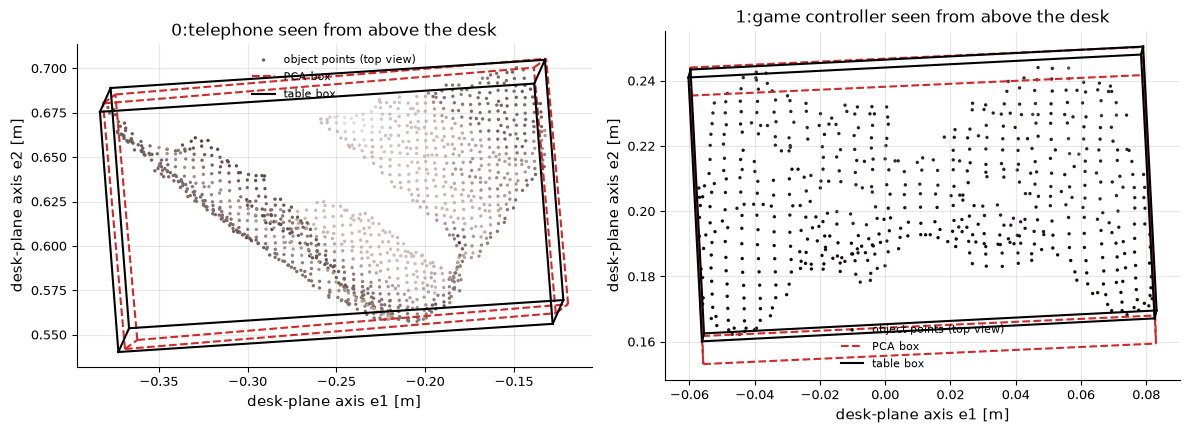

In [7]:
# --- PCA box vs table box for every object, and a top view of two objects ---
# Extents are full side lengths in cm, sorted large -> small for the PCA box.
boxes_pca = {k: g3.pca_box(c.points) for k, c in clouds.items() if c is not None}
boxes_tab = {k: g3.table_box(clouds[k].points, planes[k]) for k in boxes_pca if planes[k] is not None}
rows = []
for k, bp in boxes_pca.items():
    bt = boxes_tab.get(k)
    rows.append({"object": f"{k}:{dets.labels[k]}",
                 "PCA extents [cm]": np.round(np.sort(bp.extents)[::-1] * 100, 1),
                 # box axes have no sign: an axis anti-parallel to the normal is aligned too
                 "PCA tilt vs desk normal [deg]": round(min(min(a, 180 - a) for a in (
                     angle_between_deg(bp.R[:, j], n_med) for j in range(3))), 1),
                 "table-box L x W x H [cm]": None if bt is None else np.round(bt.extents * 100, 1)})
display(pd.DataFrame(rows).set_index("object"))

e1, e2 = g3.in_plane_basis(n_med)
show = [k for k in boxes_tab][:2]
fig, axes = plt.subplots(1, len(show), figsize=(6 * len(show), 4.6))
for ax, k in zip(np.atleast_1d(axes), show):
    P = clouds[k].points
    ax.scatter(P @ e1, P @ e2, s=2, c=clouds[k].colors, label="object points (top view)")
    for name, b, ls in [("PCA box", boxes_pca[k], "--"), ("table box", boxes_tab[k], "-")]:
        C = b.corners()
        for j, (a, c) in enumerate(g3.BOX_EDGES):
            ax.plot([C[a] @ e1, C[c] @ e1], [C[a] @ e2, C[c] @ e2], ls, lw=1.5,
                    color="k" if name == "table box" else "tab:red", label=name if j == 0 else None)
    ax.set_aspect("equal")
    ax.set_xlabel("desk-plane axis e1 [m]")
    ax.set_ylabel("desk-plane axis e2 [m]")
    ax.set_title(f"{k}:{dets.labels[k]} seen from above the desk")
    ax.legend(fontsize=8, loc="best")
plt.tight_layout()
plt.show()

## 6. Grasp synthesis: top-down antipodal grasps

We plan for a parallel-jaw gripper (defaults roughly match a Robotiq 2F-85: 85 mm stroke,
35 mm long and 22 mm wide finger pads). Gripper frame convention: origin between the pads,
$z$ = **approach** direction (into the object), $x$ = **closing** direction, $y = z \times x$.

For a table box with axes (major, minor, normal) the planner tries two closing directions
(minor axis first, then major) and 5 positions along the other in-plane axis. For each candidate:

1. the object points under the pads (a 22 mm slab) give the local **width** $w$ (1st-99th
   percentile) and top height; the gripper opens to $w + 2 \times 1$ cm clearance;
2. reject if the opening exceeds the stroke (**too wide**) or the object is lower than 12 mm
   (**too flat** to pinch from above);
3. place the pads $\tfrac12$ pad length below the local top, but keep the fingertips 3 mm above
   the table; reject if more than 8 scene/object points fall inside the closing finger volumes
   (**collision**: neighbouring objects, cables);
4. score $= 0.4\,(1 - \tfrac{\text{opening}}{\text{stroke}}) + 0.3\,\text{centring}
   + 0.3\,\overline{|\mathbf n_i^\top \mathbf x|}$, the last term being the **antipodal**
   quality: contact-surface normals should be parallel to the closing direction.

`cap.estimate_objects` chains sections 3-6 for all objects and times each stage.

In [8]:
# --- Full 3D stage for all objects: clouds, planes, boxes and grasps ---
# The scene cloud (stride 2) is used for collision checks against neighbouring objects.
timings = {}
results = cap.estimate_objects(rgb, depth, dets, masks, R, timings=timings)
for k, r in enumerate(results):
    g = r.best_grasp
    best = "no feasible grasp" if g is None else (
        f"grasp: close along {g.axis} axis, width {100 * g.width:.1f} cm, score {g.score:.2f}")
    reasons = sorted({gr.reason for gr in r.grasps if not gr.feasible})
    print(f"{k}:{r.label:16s} [{r.status}] {best}; rejected: {', '.join(reasons) or '-'}")
print("CPU stage timings [ms]:", {k: round(v, 1) for k, v in timings.items()})
k_g = next((k for k, r in enumerate(results) if r.best_grasp is not None), None)
cand = pd.DataFrame([{"axis": g.axis, "offset [cm]": round(100 * g.offset, 1),
                      "width [cm]": round(100 * g.width, 1), "opening [cm]": round(100 * g.opening, 1),
                      "feasible": g.feasible, "reason": g.reason, "score": round(g.score, 3),
                      "antipodal": None if g.parts.get("antipodal") is None
                      else round(g.parts["antipodal"], 2)}
                     for g in results[k_g].grasps])
print(f"\nall candidates for object {k_g}:{results[k_g].label}")
display(cand)

0:telephone        [ok] grasp: close along minor axis, width 4.6 cm, score 0.46; rejected: too wide (10.2 cm), too wide (12.2 cm), too wide (14.1 cm), too wide (18.8 cm), too wide (22.3 cm), too wide (23.7 cm), too wide (8.4 cm), too wide (9.6 cm)
1:game controller  [ok] grasp: close along minor axis, width 4.2 cm, score 0.46; rejected: too wide (12.4 cm), too wide (13.0 cm), too wide (13.6 cm), too wide (13.8 cm), too wide (7.6 cm), too wide (8.0 cm)
2:keyboard         [ok] grasp: close along minor axis, width 3.0 cm, score 0.46; rejected: too wide (11.5 cm), too wide (6.5 cm), too wide (9.9 cm)
3:book             [ok] grasp: close along minor axis, width 4.0 cm, score 0.27; rejected: too wide (10.6 cm), too wide (11.2 cm), too wide (12.6 cm), too wide (14.0 cm), too wide (19.2 cm), too wide (22.1 cm), too wide (27.3 cm), too wide (8.9 cm), too wide (9.4 cm)
4:cereal box       [ok] grasp: close along minor axis, width 3.8 cm, score 0.68; rejected: too wide (10.9 cm), too wide (7.7 cm)

,axis,offset [cm],width [cm],opening [cm],feasible,reason,score,antipodal
0,minor,-4.3,4.6,6.6,True,ok,0.462,0.59
1,minor,-8.6,3.1,5.1,True,ok,0.458,0.70
2,minor,0.0,10.2,12.2,False,too wide (10.2 cm),0.000,NaN
3,minor,4.3,12.2,14.2,False,too wide (12.2 cm),0.000,NaN
4,minor,8.6,9.6,11.6,False,too wide (9.6 cm),0.000,NaN
5,major,-4.8,8.4,10.4,False,too wide (8.4 cm),0.000,NaN
6,major,-2.4,14.1,16.1,False,too wide (14.1 cm),0.000,NaN
7,major,0.0,18.8,20.8,False,too wide (18.8 cm),0.000,NaN
8,major,2.4,22.3,24.3,False,too wide (22.3 cm),0.000,NaN
9,major,4.8,23.7,25.7,False,too wide (23.7 cm),0.000,NaN


## 7. Coordinate frames: camera → world

The planner works in the **camera optical frame** ($x$ right, $y$ down, $z$ forward). A robot
needs the grasp in its own base or map frame. Here the motion-capture system plays the role of
the robot's localisation: TUM provides $T_{wc}$ (camera → world), so

$$ T_{wg} = T_{wc}\, T_{cg}, \qquad \mathbf p_w = R_{wc}\,\mathbf p_c + \mathbf t_{wc}. $$

On a real robot, $T_{wc}$ would come from TF: `base_link → … → camera_color_optical_frame`.
Quaternions follow the ROS / SciPy order $(x, y, z, w)$.

In [9]:
# --- Best grasp of one object in the camera and in the world frame ---
# The round trip T_cg = T_wc^-1 T_wg checks the chain; approach angle = angle between the
# gripper z axis and the world -z axis.
g = results[k_g].best_grasp
T_cg = g.T
T_wg = T_wc @ T_cg
print(f"object {k_g}:{results[k_g].label}")
print("T_cg (gripper in camera frame):\n", T_cg)
print("T_wg (gripper in world frame):\n", T_wg)
print("position camera [m]:", T_cg[:3, 3], " world [m]:", T_wg[:3, 3])
print("quaternion xyzw camera:", R_to_quat(T_cg[:3, :3]), " world:", R_to_quat(T_wg[:3, :3]))
print(f"round-trip error: {np.abs(invert_T(T_wc) @ T_wg - T_cg).max():.2e}")
print(f"approach axis vs world -z: {angle_between_deg(T_wg[:3, 2], [0, 0, -1]):.1f} deg, "
      f"gripper opening {100 * g.opening:.1f} cm")

object 0:telephone
T_cg (gripper in camera frame):
 [[-0.083  0.989 -0.12  -0.315]
 [-0.719  0.024  0.694 -0.268]
 [ 0.69   0.144  0.709  0.694]
 [ 0.     0.     0.     1.   ]]
T_wg (gripper in world frame):
 [[-0.641  0.767  0.025  0.367]
 [ 0.755  0.636 -0.16   0.296]
 [-0.139 -0.084 -0.987  0.839]
 [ 0.     0.     0.     1.   ]]
position camera [m]: [-0.315 -0.268  0.694]  world [m]: [0.367 0.296 0.839]
quaternion xyzw camera: [-0.214 -0.315 -0.665  0.642]  world: [ 0.421  0.903 -0.068  0.045]
round-trip error: 3.33e-16
approach axis vs world -z: 9.3 deg, gripper opening 6.6 cm


## 8. Monocular metric depth instead of the depth sensor

Could a robot with only an RGB camera do the same? *Depth Anything V2 Metric-Indoor-Small*
(25 M params, fine-tuned on synthetic Hypersim indoor scenes) predicts depth in metres from one
image. We compare it with the Kinect depth on the valid pixels (AbsRel
$=\tfrac1N\sum |\hat z - z|/z$, $\delta_1$ = share of pixels with $\max(\hat z/z, z/\hat z) < 1.25$),
raw and after a per-frame median scale $s = \mathrm{med}(z)/\mathrm{med}(\hat z)$, an oracle
correction that a robot would *not* have at run time. Then we run the 3D stage with each depth
and measure how far the object centroids move.

DA-V2 Metric-Indoor-S: 40 ms, peak VRAM 386 MiB, median scale sensor/mono = 0.536


,sensor box [cm],mono raw: centroid offset [cm],mono raw: box [cm],mono median-scaled: centroid offset [cm],mono median-scaled: box [cm]
object,,,,,
0:telephone,"[24.6, 13.7, 8.8]",58.3,"[47.2, 17.2, 22.7]",6.2,"[25.3, 9.2, 12.2]"
1:game controller,"[13.9, 8.1, 6.8]",51.5,"[28.9, 18.6, 8.6]",4.7,"[15.4, 10.2, 4.6]"
2:keyboard,"[14.0, 6.2, 3.4]",51.9,"[27.5, 18.2, 7.6]",16.2,"[15.8, 9.2, 4.2]"
3:book,"[28.5, 14.1, 4.1]",60.5,"[43.3, 27.3, 11.3]",1.2,"[23.1, 14.5, 5.9]"
4:cereal box,"[11.6, 6.0, 15.1]",55.2,"[27.9, 12.6, 32.1]",2.3,"[15.8, 7.6, 15.5]"
5:book,"[26.5, 22.1, 1.8]",48.7,"[50.6, 22.6, 9.6]",13.1,"[26.9, 12.2, 3.6]"


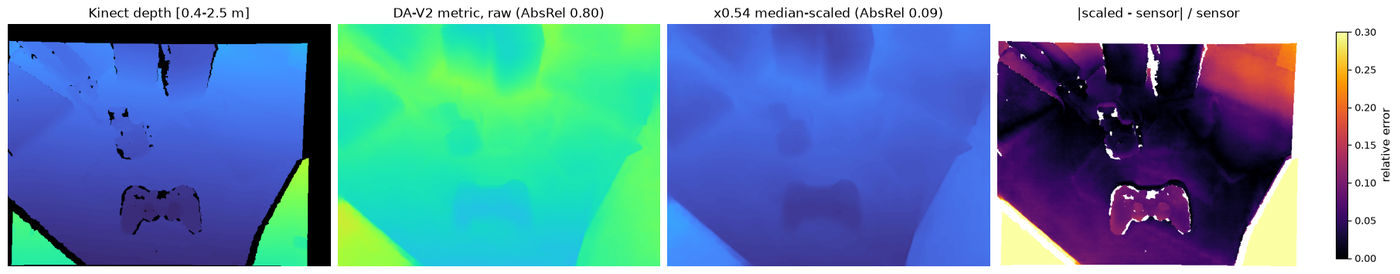

In [10]:
# --- Depth Anything V2 Metric-Indoor-S vs the Kinect depth, and its effect on the 3D objects ---
# Mono depth is dense (no holes), so the object clouds use more pixels than with the sensor.
cvdevice.reset_peak_vram()
with cvdevice.track_vram() as mem:
    mono_model = cap.MetricDepth(DEV)
    mono = mono_model.predict(rgb)
mono_lat = benchmark(mono_model.predict, rgb, warmup=2, iters=5)
mono_vram = mem.peak_mb
del mono_model
cap.free()
valid = depth > 0
scale = align_depth_scale(mono, depth, valid)
dm = {"raw": depth_metrics(mono, depth, valid), "median-scaled": depth_metrics(scale * mono, depth, valid)}
print(f"DA-V2 Metric-Indoor-S: {mono_lat['mean_ms']:.0f} ms, peak VRAM {mono_vram:.0f} MiB, "
      f"median scale sensor/mono = {scale:.3f}")
depth_runs = {"sensor": depth, "mono raw": mono, "mono median-scaled": scale * mono}
obj3d = {name: cap.estimate_objects(rgb, d, dets, masks, R, grasps=False) for name, d in depth_runs.items()}
rows = []
for k, lab in enumerate(dets.labels):
    ref = obj3d["sensor"][k]
    if ref.box is None:
        continue
    row = {"object": f"{k}:{lab}", "sensor box [cm]": np.round(ref.box.extents * 100, 1)}
    for name in ["mono raw", "mono median-scaled"]:
        o = obj3d[name][k]
        row[f"{name}: centroid offset [cm]"] = (None if o.cloud is None else
                                                round(100 * float(np.linalg.norm(o.centroid - ref.centroid)), 1))
        row[f"{name}: box [cm]"] = None if o.box is None else np.round(o.box.extents * 100, 1)
    rows.append(row)
mono_obj = pd.DataFrame(rows).set_index("object")
display(mono_obj)

fig, axes = plt.subplots(1, 4, figsize=(18, 3.9))
axes[0].imshow(viz.colorize_depth(depth, vmin=0.4, vmax=2.5))
axes[0].set_title("Kinect depth [0.4-2.5 m]")
axes[1].imshow(viz.colorize_depth(mono, vmin=0.4, vmax=2.5))
axes[1].set_title(f"DA-V2 metric, raw (AbsRel {dm['raw']['abs_rel']:.2f})")
axes[2].imshow(viz.colorize_depth(scale * mono, vmin=0.4, vmax=2.5))
axes[2].set_title(f"x{scale:.2f} median-scaled (AbsRel {dm['median-scaled']['abs_rel']:.2f})")
err = np.where(valid, np.abs(scale * mono - depth) / np.maximum(depth, 1e-6), np.nan)
im = axes[3].imshow(err, cmap="inferno", vmin=0, vmax=0.3)
axes[3].set_title("|scaled - sensor| / sensor")
fig.colorbar(im, ax=axes[3], fraction=0.035, label="relative error")
for a in axes:
    a.axis("off")
plt.show()

## Results

The final output for frame 540: masks, gravity-aligned 3D boxes projected back into the image
(through the distorted lens model) and the best grasp per object (red bar = finger opening, short
stem = approach direction), plus the same scene in 3D. Measured on an RTX 5060 Laptop GPU (models)
and an Intel Core Ultra 9 275HX (geometry).

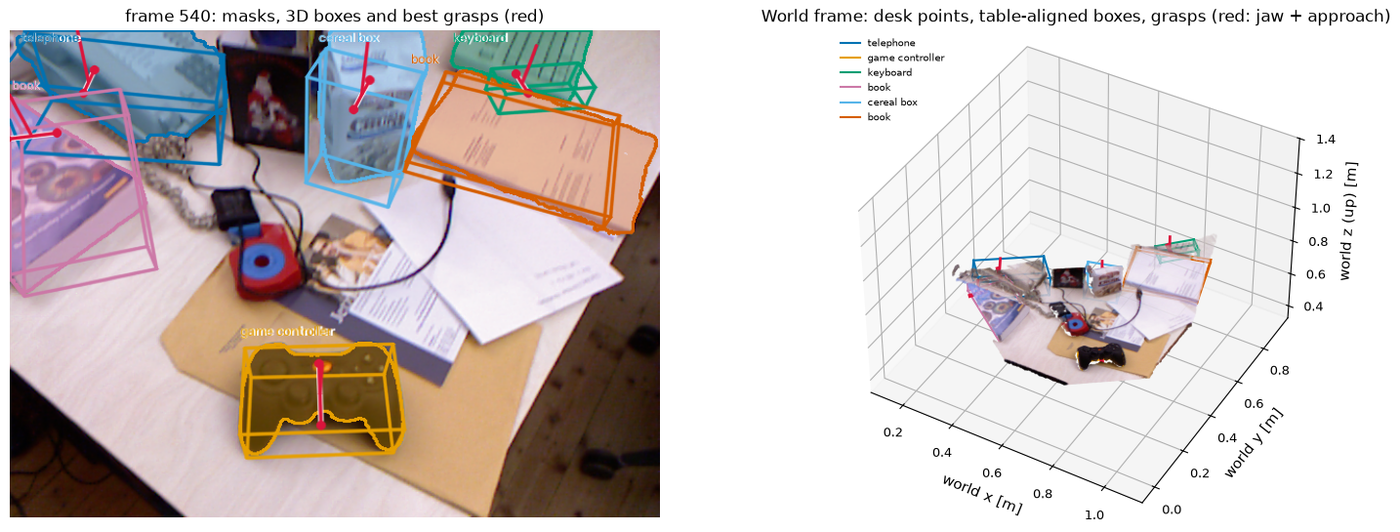

In [11]:
# --- Final pipeline output: image overlay and 3D view in the world frame (z up) ---
# Notebook section 4 showed that the motion-capture world z axis is the desk normal, so the 3D
# view uses world coordinates; scene points are cropped to the region around the objects.
overlay_img = cap.draw_results(rgb, results, K, D)
scene, scene_pix = g3.backproject(depth, R, stride=2)
scene_w = scene @ T_wc[:3, :3].T + T_wc[:3, 3]
boxes_w = [(r.label, r.box.transformed(T_wc), r.best_grasp) for r in results if r.box is not None]
C_all = np.concatenate([b.corners() for _, b, _ in boxes_w])
lo, hi = C_all.min(0) - [0.1, 0.1, 0.05], C_all.max(0) + [0.1, 0.1, 0.1]
keep = np.all((scene_w > lo) & (scene_w < hi), axis=1)
fig = plt.figure(figsize=(16, 5.6))
ax0 = fig.add_subplot(1, 2, 1)
ax0.imshow(overlay_img)
ax0.set_title("frame 540: masks, 3D boxes and best grasps (red)")
ax0.axis("off")
ax = fig.add_subplot(1, 2, 2, projection="3d")
ax.scatter(*scene_w[keep].T, c=rgb[scene_pix[keep, 0], scene_pix[keep, 1]] / 255, s=0.4, alpha=0.6)
for kk, (lab, b, g) in enumerate(boxes_w):
    C = b.corners()
    for j, (a, c) in enumerate(g3.BOX_EDGES):
        ax.plot(*np.stack([C[a], C[c]]).T, color=viz.color(kk, unit=True), lw=1.5,
                label=lab if j == 0 else None)
    if g is not None:
        gT = T_wc @ g.T
        p, x, zax = gT[:3, 3], gT[:3, 0], gT[:3, 2]
        ax.plot(*np.stack([p - x * g.opening / 2, p + x * g.opening / 2]).T, color="crimson", lw=3)
        ax.plot(*np.stack([p, p - zax * 0.08]).T, color="crimson", lw=2)
ax.set_xlabel("world x [m]")
ax.set_ylabel("world y [m]")
ax.set_zlabel("world z (up) [m]")
ax.view_init(elev=40, azim=-60)
viz.set_axes_equal(ax)
ax.legend(fontsize=7, loc="upper left")
ax.set_title("World frame: desk points, table-aligned boxes, grasps (red: jaw + approach)")
plt.tight_layout()
viz.savefig(fig, PROJECT, "pipeline_frame540")
plt.show()

Per-object summary (sensor depth, fr1 camera model with distortion) and the monocular-depth
comparison as a chart.

,score,status,cloud points,box,extents [cm],centroid world [m],grasp width [cm],grasp score
object,,,,,,,,
0:telephone,0.76,ok,1163,table,"[24.6, 13.7, 8.8]","[0.413, 0.334, 0.82]",4.6,0.46
1:game controller,0.65,ok,570,table,"[13.9, 8.1, 6.8]","[0.857, 0.136, 0.807]",4.2,0.46
2:keyboard,0.52,ok,256,table,"[14.0, 6.2, 3.4]","[0.815, 0.763, 0.795]",3.0,0.46
3:book,0.55,ok,1482,table,"[28.5, 14.1, 4.1]","[0.452, 0.164, 0.794]",4.0,0.27
4:cereal box,0.56,ok,835,table,"[11.6, 6.0, 15.1]","[0.71, 0.428, 0.86]",3.8,0.68
5:book,0.38,ok,2480,table,"[26.5, 22.1, 1.8]","[0.842, 0.637, 0.766]",NaN,NaN


,abs_rel,rmse [m],delta1,latency [ms],peak VRAM [MiB]
raw,0.804,0.509,0.079,40.2,386
median-scaled,0.088,0.166,0.906,40.2,386


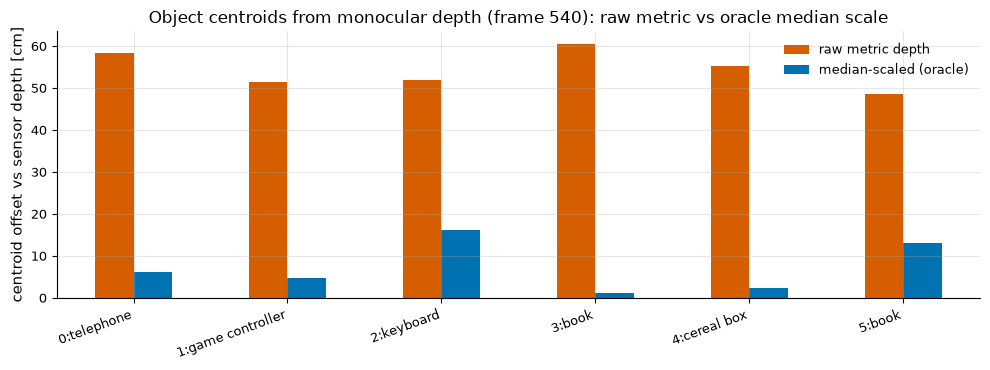

In [12]:
# --- Summary tables and the mono-vs-sensor centroid chart ---
# World-frame positions use the motion-capture pose; extents are length x width x height.
world = {d["label"] + str(i): d for i, d in enumerate(cap.to_world(T_wc, results))}
rows = []
for k, r in enumerate(results):
    g = r.best_grasp
    rows.append({"object": f"{k}:{r.label}", "score": round(r.score, 2), "status": r.status,
                 "cloud points": 0 if r.cloud is None else len(r.cloud.points),
                 "box": None if r.box is None else r.box.kind,
                 "extents [cm]": None if r.box is None else np.round(r.box.extents * 100, 1),
                 "centroid world [m]": None if r.cloud is None else np.round(T_wc[:3, :3] @ r.centroid + T_wc[:3, 3], 3),
                 "grasp width [cm]": None if g is None else round(100 * g.width, 1),
                 "grasp score": None if g is None else round(g.score, 2)})
obj_df = pd.DataFrame(rows).set_index("object")
display(obj_df)
dm_df = pd.DataFrame(dm).T[["abs_rel", "rmse", "delta1"]].rename(columns={"rmse": "rmse [m]"})
dm_df["latency [ms]"] = round(mono_lat["mean_ms"], 1)
dm_df["peak VRAM [MiB]"] = round(mono_vram)
display(dm_df.round(3))

cols = [c for c in mono_obj.columns if "offset" in c]
fig, ax = plt.subplots(figsize=(10, 3.8))
mono_obj[cols].plot.bar(ax=ax, color=[viz.color(5, unit=True), viz.color(0, unit=True)])
ax.set_ylabel("centroid offset vs sensor depth [cm]")
ax.set_xlabel("")
ax.set_title(f"Object centroids from monocular depth (frame {FID}): raw metric vs oracle median scale")
ax.legend(["raw metric depth", "median-scaled (oracle)"])
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
viz.savefig(fig, PROJECT, "mono_vs_sensor")
plt.show()
_ = cap.results_dir().joinpath("nb02_frame540_objects.csv").write_text(obj_df.to_csv())
_ = cap.results_dir().joinpath("nb02_mono_depth.csv").write_text(dm_df.to_csv())

### Takeaways

- **Depth coverage is the first bottleneck, cleaning the second.** Only 26 % of the keyboard's
  mask pixels and 59 % of the phone's have a depth value (dark plastic, image border), and the
  3 px erosion removes another 7-27 % of the pixels with depth (thin objects lose the most). The median/MAD gate only bites where a mask leaks
  (the game controller loses about 9 % of its points to it), but there it keeps desk points
  out of the object.
- **Use the support plane.** The six local plane fits agree within 2.2 deg except next to the
  phone (9.6 deg, a cluttered ring), and their median normal is within 0.6 deg of the
  motion-capture world z axis, so the desk normal is a reliable gravity estimate. PCA boxes of the
  partial views are tilted by up to 13 deg or report a surface thickness as the height (the upright rusk box:
  7.2 cm PCA thickness vs a 15.1 cm table-box height); the table-aligned box sits on the desk.
- **Graspability is mostly geometry**: with an 85 mm stroke most closing directions on the books
  and the phone are rejected as *too wide*, the flat document stack as *too flat*. The
  heuristic still accepts some questionable grasps on partial clouds (the cut-off keyboard at the
  image border, the edge of a book), which is why a real system adds a learned grasp-quality model
  and closed-loop checks.
- **Frames**: the planner's output is a camera-frame pose; one matrix product with the localised
  camera pose gives the world-frame grasp (round-trip error at machine precision), with the
  approach axis 9.3 deg from vertical.
- **Monocular metric depth is not a drop-in replacement here.** Depth Anything V2
  Metric-Indoor-S places this close-range desk about 1.9x too far (median scale 0.54, AbsRel
  0.80), moving the object centroids by about half a metre. Even with an oracle per-frame scale
  (AbsRel 0.088), centroids move by 1-16 cm and the boxes change shape. Use it to fill sensor holes
  or for coarse navigation, not for grasping.

## Exercises

**Exercise 1 - a bigger gripper.** Re-run the grasp planner with `g3.Gripper(max_opening=0.14)`
(a 140 mm stroke, e.g. a Robotiq 2F-140). Which objects become graspable, along which axis, and
how do the scores change?

In [13]:
# --- Exercise 1: grasps with a 140 mm gripper (TODO) ---
# TODO: results_big = cap.estimate_objects(rgb, depth, dets, masks, R, gripper=g3.Gripper(max_opening=0.14))
#       and compare the best grasps with `results`.

**Exercise 2 - ablate the cloud cleaning.** Build the object clouds with `erode_px=0` and an
effectively disabled depth gate (`gate_k=1e9`), then compute table boxes. How much do the box
extents and heights change per object compared with the default cleaning?

In [14]:
# --- Exercise 2: no erosion, no depth gate (TODO) ---
# TODO: g3.object_cloud(depth, masks[k], R, rgb, erode_px=0, gate_k=1e9) for every object, then
#       g3.table_box(cloud.points, planes[k]) and compare the extents with boxes_tab.

**Exercise 3 - grasping from monocular depth.** Run the full 3D stage (with grasps) on the
median-scaled monocular depth. Which objects still get a feasible grasp, and how far (cm) is each
grasp position from the sensor-based grasp?

In [15]:
# --- Exercise 3: grasps from scaled monocular depth (TODO) ---
# TODO: results_mono = cap.estimate_objects(rgb, scale * mono, dets, masks, R) and compare
#       best_grasp.position with the sensor results.